# практика 3
сверточные нейросети

подключаем библиотеки и готовим картинки

In [1]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import CIFAR10, GTSRB
from torchvision.transforms import v2
from torchvision import utils
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = v2.Compose([
    v2.Resize((32, 32)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])
print(device)

cpu


делаем свою сеть на основе LeNet добавляем еще одну свертку

In [2]:
class CNN(nn.Module):
    def __init__(self, classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.max_pool2d(F.relu(self.conv3(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

пишем обучение и считаем loss и accuracy для train и val

In [3]:
def train_model(model, train_loader, val_loader, epochs=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        for part, loader in [("train", train_loader), ("val", val_loader)]:
            if part == "train":
                model.train()
            else:
                model.eval()

            total_loss, correct, total = 0, 0, 0
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                if part == "train":
                    optimizer.zero_grad()
                with torch.set_grad_enabled(part == "train"):
                    out = model(x)
                    loss = loss_fn(out, y)
                    if part == "train":
                        loss.backward()
                        optimizer.step()
                total_loss += loss.item() * len(y)
                correct += (out.argmax(1) == y).sum().item()
                total += len(y)

            history[part + "_loss"].append(total_loss / total)
            history[part + "_acc"].append(correct / total)
        print(f"эпоха {epoch + 1}  train {history['train_acc'][-1]:.3f}  val {history['val_acc'][-1]:.3f}")
    return history

делаем графики ошибки и точности

In [4]:
def show_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for part in ["train", "val"]:
        ax[0].plot(history[part + "_loss"], label=part)
        ax[1].plot(history[part + "_acc"], label=part)
    ax[0].set_title("loss")
    ax[1].set_title("accuracy")
    ax[0].legend()
    ax[1].legend()
    plt.show()

проверяем модель на тестовых картинках

In [5]:
def test_model(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            correct += (out.argmax(1).cpu() == y).sum().item()
            total += len(y)
    return correct / total

показываем карты признаков последней свертки

In [6]:
def show_maps(model, dataset):
    maps = []

    def hook(module, inputs, output):
        maps.append(output.cpu())

    handle = model.conv3.register_forward_hook(hook)
    image, label = dataset[0]
    model.eval()
    with torch.no_grad():
        pred = model(image.unsqueeze(0).to(device))
    handle.remove()

    grid = utils.make_grid(F.relu(maps[0][0][:16]).unsqueeze(1), nrow=4, normalize=True)
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(f"класс {label}  ответ {pred.argmax(1).item()}")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.title("карты признаков")
    plt.axis("off")
    plt.show()

## CIFAR 10
скачиваем картинки и делим на train val test

In [7]:
cifar_all = CIFAR10(root="./data", train=True, download=True, transform=transform)
cifar_test = CIFAR10(root="./data", train=False, download=True, transform=transform)
cifar_train, cifar_val = random_split(cifar_all, [40000, 10000])
cifar_train_loader = DataLoader(cifar_train, batch_size=128, shuffle=True)
cifar_val_loader = DataLoader(cifar_val, batch_size=128)
cifar_test_loader = DataLoader(cifar_test, batch_size=128)
print(len(cifar_train), len(cifar_val), len(cifar_test))

100.0%


40000 10000 10000


обучаем модель на 10 классах

In [8]:
cifar_model = CNN(10).to(device)
cifar_history = train_model(cifar_model, cifar_train_loader, cifar_val_loader, epochs=5)

эпоха 1  train 0.351  val 0.367
эпоха 2  train 0.472  val 0.486
эпоха 3  train 0.531  val 0.551
эпоха 4  train 0.571  val 0.596
эпоха 5  train 0.605  val 0.610


смотрим как менялись ошибка и точность

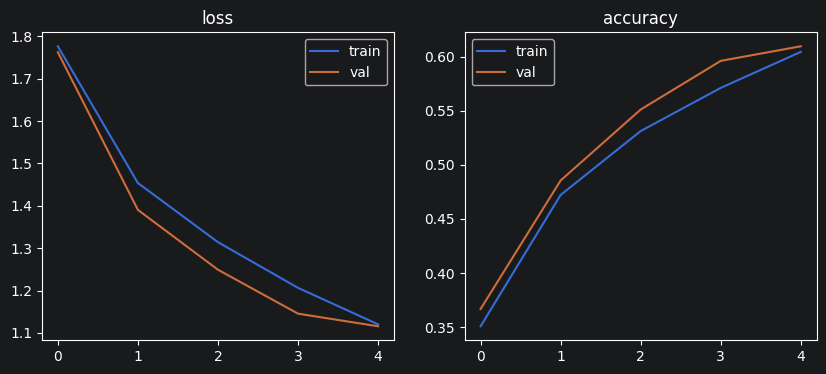

In [9]:
show_history(cifar_history)

считаем сколько параметров у модели

In [10]:
cifar_params = sum(torch.tensor(p.shape).prod().item() for p in cifar_model.parameters())
print("параметров", cifar_params)

параметров 156074


проверяем точность на test

In [11]:
print("CIFAR 10 test accuracy", test_model(cifar_model, cifar_test_loader))

CIFAR 10 test accuracy 0.5982


смотрим что выделяет последний сверточный слой

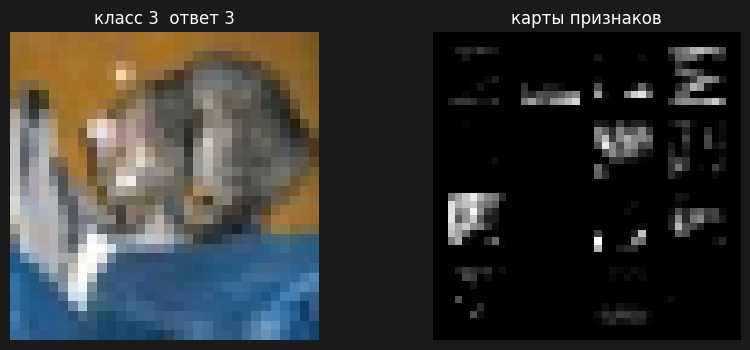

In [12]:
show_maps(cifar_model, cifar_test)

## GTSRB
теперь берем более сложный датасет с 43 видами дорожных знаков

In [15]:
signs_all = GTSRB(root="./data", split="train", download=True, transform=transform)
signs_test = GTSRB(root="./data", split="test", download=True, transform=transform)
signs_train, signs_val = random_split(signs_all, [int(len(signs_all) * 0.8), len(signs_all) - int(len(signs_all) * 0.8)])
signs_train_loader = DataLoader(signs_train, batch_size=128, shuffle=True)
signs_val_loader = DataLoader(signs_val, batch_size=128)
signs_test_loader = DataLoader(signs_test, batch_size=128)
print(len(signs_train), len(signs_val), len(signs_test))

100.0%
100.0%
100.0%


21312 5328 12630


обучаем такую же сеть но теперь на 43 классах

In [16]:
signs_model = CNN(43).to(device)
signs_history = train_model(signs_model, signs_train_loader, signs_val_loader, epochs=5)

эпоха 1  train 0.129  val 0.275
эпоха 2  train 0.404  val 0.492
эпоха 3  train 0.597  val 0.684
эпоха 4  train 0.759  val 0.794
эпоха 5  train 0.846  val 0.875


строим графики для дорожных знаков

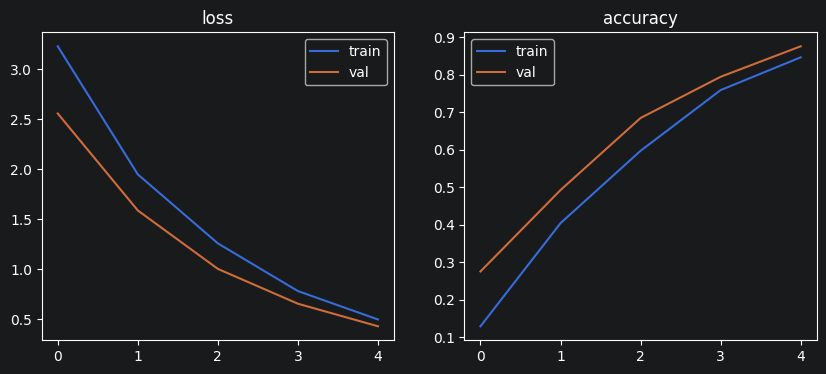

In [17]:
show_history(signs_history)

считаем параметры второй модели

In [18]:
signs_params = sum(torch.tensor(p.shape).prod().item() for p in signs_model.parameters())
print("параметров", signs_params)

параметров 160331


смотрим качество на test

In [19]:
print("GTSRB test accuracy", test_model(signs_model, signs_test_loader))

GTSRB test accuracy 0.6702296120348377


смотрим карты признаков на дорожном знаке

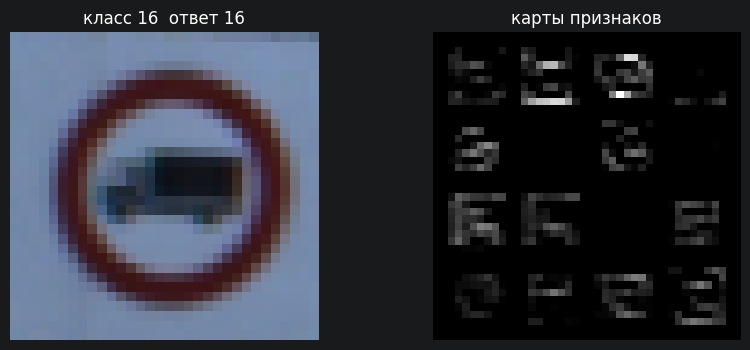

In [20]:
show_maps(signs_model, signs_test)

## вывод
обучили сверточную сеть на двух датасетах и проверили точность. на картах признаков светлые участки показывают где фильтр сильнее реагирует на картинку